# 04: Monte Carlo Simulation

## 目的
TWFEの期間別推定で観察されたsign flipが、treatment effect heterogeneityや
非線形dose-responseの下で自然に生じるかをシミュレーションで検証する。

## 方法
1. **処置パスを実データから固定**: 47都道府県の最低賃金年度ベースのlog(MW)系列を使う
2. **アウトカムだけ生成**: Y_iy = alpha_i + gamma_y + tau(d_iy) + epsilon_iy
3. **TWFEで推定**: 前期(2013-2017)と後期(2020-2024)に分けてbeta_hatを計算
4. **sign flipの発生率を測定**: sign(beta_hat_early) != sign(beta_hat_late) の割合

## DGPバリエーション
| DGP | tau(d) | TWFEの想定 |
|-----|------|------------|
| A: 線形・均質 | beta*d | 正しく推定可能 |
| B: 非線形 | beta*d + kappa*d^2 | estimand problem |
| C: 異質 | beta_i*d | negative weight問題 |
| D: 両方 | beta_i*d + kappa*d^2 | 両方の問題 |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

plt.style.use('seaborn-v0_8-whitegrid')
import japanize_matplotlib

np.random.seed(2026)

## Step 1: 実データから年次MWパスを取得

In [2]:
annual = pd.read_csv('../data/annual_panel.csv')

# TWFE・dcDHと同じ完全年サンプル
clean_years = [2013, 2014, 2015, 2016, 2017, 2020, 2021, 2022, 2023, 2024]
mw_paths = annual[annual.mw_year.isin(clean_years)][['pref_code', 'mw_year', 'log_mw']].copy()
mw_paths = mw_paths.sort_values(['pref_code', 'mw_year']).reset_index(drop=True)

# entity/time のインデックス
prefs = sorted(mw_paths.pref_code.unique())
years = sorted(mw_paths.mw_year.unique())
pref_to_idx = {p: i for i, p in enumerate(prefs)}
year_to_idx = {t: i for i, t in enumerate(years)}

mw_paths['pref_idx'] = mw_paths.pref_code.map(pref_to_idx)
mw_paths['ym_idx'] = mw_paths.mw_year.map(year_to_idx)  # downstream code uses ym_idx as a generic time index

N_pref = len(prefs)
N_time = len(years)
N = len(mw_paths)

# 前期・後期のマスク
early_mask = (mw_paths.mw_year <= 2017).values
late_mask = (mw_paths.mw_year >= 2020).values

# 固定する処置変数
d = mw_paths.log_mw.values
pref_idx = mw_paths.pref_idx.values
ym_idx = mw_paths.ym_idx.values

print(f'都道府県数: {N_pref}, 時点数: {N_time}, 総観測数: {N}')
print(f'前期(2013-2017): {early_mask.sum()} obs, 後期(2020-2024): {late_mask.sum()} obs')
print(f'log(MW) std: {d.std():.4f}')


都道府県数: 47, 時点数: 10, 総観測数: 470
前期(2013-2017): 235 obs, 後期(2020-2024): 235 obs
log(MW) std: 0.1286


## Step 2: 高速TWFE推定関数

Frisch-Waugh-Lovell定理により、entity FE + time FEを除去してOLSするのと
PanelOLSは同値。1000回回すので高速版を使う。

In [3]:
def demean(x, entity_ids, time_ids):
    """entity + time FEを除去（double demeaning）"""
    x = x.copy()
    # entity demeaning
    for g in np.unique(entity_ids):
        mask = entity_ids == g
        x[mask] -= x[mask].mean()
    # time demeaning
    for g in np.unique(time_ids):
        mask = time_ids == g
        x[mask] -= x[mask].mean()
    return x

def twfe_beta(Y, d, entity_ids, time_ids):
    """TWFE推定値β̂を返す（FWL demeaning + OLS）"""
    Y_dm = demean(Y, entity_ids, time_ids)
    d_dm = demean(d, entity_ids, time_ids)
    return np.sum(d_dm * Y_dm) / np.sum(d_dm ** 2)

# 速度テスト
import time
Y_test = np.random.randn(N)
t0 = time.time()
for _ in range(100):
    twfe_beta(Y_test, d, pref_idx, ym_idx)
elapsed = time.time() - t0
print(f'TWFE 1回あたり: {elapsed/100*1000:.1f} ms')
print(f'1000回 × 3(full/early/late) × 4(DGP) = {elapsed/100*12000:.0f} 秒 の見込み')

TWFE 1回あたり: 1.4 ms


1000回 × 3(full/early/late) × 4(DGP) = 16 秒 の見込み


## Step 3: DGP定義

パラメータは年次パネルでのTWFE/dcDH比較に合わせる:
- 処置パスは最低賃金年度ベースの実データ
- アウトカムは人工的に生成
- sigma_eps = 0.018 は月次TWFE時の残差ノイズをベースにした暫定値


In [4]:
SIGMA_EPS = 0.018  # 残差ノイズ（実データからキャリブレーション）
BETA_TRUE = 0.3    # 真の平均効果

def generate_Y(d, pref_idx, ym_idx, N_pref, N_time,
               beta=BETA_TRUE, kappa=0.0, sigma_het=0.0,
               sigma_eps=SIGMA_EPS):
    """
    DGPに従ってアウトカムを生成する。
    
    Y_it = alpha_i + gamma_t + tau(d_it) + eps_it
    
    Parameters
    ----------
    d : array - 実データのlog(MW)（固定）
    beta : float - 平均効果
    kappa : float - 非線形パラメータ。0=線形、≠0でd²項が入る
    sigma_het : float - 効果の異質性。0=均質、>0で県ごとにβが異なる
    sigma_eps : float - ノイズの標準偏差
    """
    N = len(d)
    
    # 固定効果
    alpha = np.random.normal(0, 0.1, N_pref)
    gamma = np.random.normal(0, 0.05, N_time)
    
    # 処置効果
    if sigma_het > 0:
        beta_i = np.random.normal(beta, sigma_het, N_pref)
        tau = beta_i[pref_idx] * d + kappa * d ** 2
    else:
        tau = beta * d + kappa * d ** 2
    
    # ノイズ
    eps = np.random.normal(0, sigma_eps, N)
    
    return alpha[pref_idx] + gamma[ym_idx] + tau + eps

# DGP設定
DGPS = {
    'A: 線形・均質':    {'kappa': 0.0,   'sigma_het': 0.0},
    'B: 非線形':        {'kappa': 0.05,  'sigma_het': 0.0},
    'C: 異質':          {'kappa': 0.0,   'sigma_het': 0.5},
    'D: 非線形+異質':   {'kappa': 0.05,  'sigma_het': 0.5},
}

print('DGP設定:')
for name, params in DGPS.items():
    print(f'  {name}: kappa={params["kappa"]}, sigma_het={params["sigma_het"]}')

DGP設定:
  A: 線形・均質: kappa=0.0, sigma_het=0.0
  B: 非線形: kappa=0.05, sigma_het=0.0
  C: 異質: kappa=0.0, sigma_het=0.5
  D: 非線形+異質: kappa=0.05, sigma_het=0.5


## Step 4: MCループ

各DGPについて1000回繰り返し、毎回:
1. Yを生成
2. 前期(2013-2017)・後期(2020-2024)でTWFEを推定
3. sign(beta_hat_early) != sign(beta_hat_late) かチェック


In [5]:
N_REP = 1000

# 前期・後期のインデックス（固定）
d_early = d[early_mask]
d_late = d[late_mask]
pref_early = pref_idx[early_mask]
pref_late = pref_idx[late_mask]
ym_early = ym_idx[early_mask]
ym_late = ym_idx[late_mask]

results = {}

for dgp_name, params in DGPS.items():
    betas_full = np.zeros(N_REP)
    betas_early = np.zeros(N_REP)
    betas_late = np.zeros(N_REP)
    
    for r in tqdm(range(N_REP), desc=dgp_name):
        Y = generate_Y(d, pref_idx, ym_idx, N_pref, N_time, **params)
        
        betas_full[r] = twfe_beta(Y, d, pref_idx, ym_idx)
        betas_early[r] = twfe_beta(Y[early_mask], d_early, pref_early, ym_early)
        betas_late[r] = twfe_beta(Y[late_mask], d_late, pref_late, ym_late)
    
    sign_flip = np.sign(betas_early) != np.sign(betas_late)
    
    results[dgp_name] = {
        'full': betas_full,
        'early': betas_early,
        'late': betas_late,
        'flip_rate': sign_flip.mean(),
        'bias_full': betas_full.mean() - BETA_TRUE,
    }
    
    print(f'\n{dgp_name}:')
    print(f'  β̂ full:  mean={betas_full.mean():.4f}, std={betas_full.std():.4f}')
    print(f'  β̂ early: mean={betas_early.mean():.4f}, std={betas_early.std():.4f}')
    print(f'  β̂ late:  mean={betas_late.mean():.4f}, std={betas_late.std():.4f}')
    print(f'  Sign flip rate: {sign_flip.mean():.1%}')

A: 線形・均質:   0%|          | 0/1000 [00:00<?, ?it/s]

A: 線形・均質:   1%|▏         | 14/1000 [00:00<00:07, 137.47it/s]

A: 線形・均質:   3%|▎         | 34/1000 [00:00<00:05, 173.53it/s]

A: 線形・均質:   5%|▌         | 52/1000 [00:00<00:05, 171.71it/s]

A: 線形・均質:   7%|▋         | 70/1000 [00:00<00:05, 156.22it/s]

...

D: 非線形+異質:  96%|█████████▌| 960/1000 [00:05<00:00, 153.27it/s]

D: 非線形+異質:  98%|█████████▊| 976/1000 [00:05<00:00, 140.16it/s]

D: 非線形+異質:  99%|█████████▉| 991/1000 [00:05<00:00, 130.58it/s]

D: 非線形+異質: 100%|██████████| 1000/1000 [00:05<00:00, 172.02it/s]


D: 非線形+異質:
  β̂ full:  mean=0.8965, std=1.0382
  β̂ early: mean=0.8790, std=1.0974
  β̂ late:  mean=0.9374, std=0.8102
  Sign flip rate: 29.0%


## Step 5: 結果の可視化

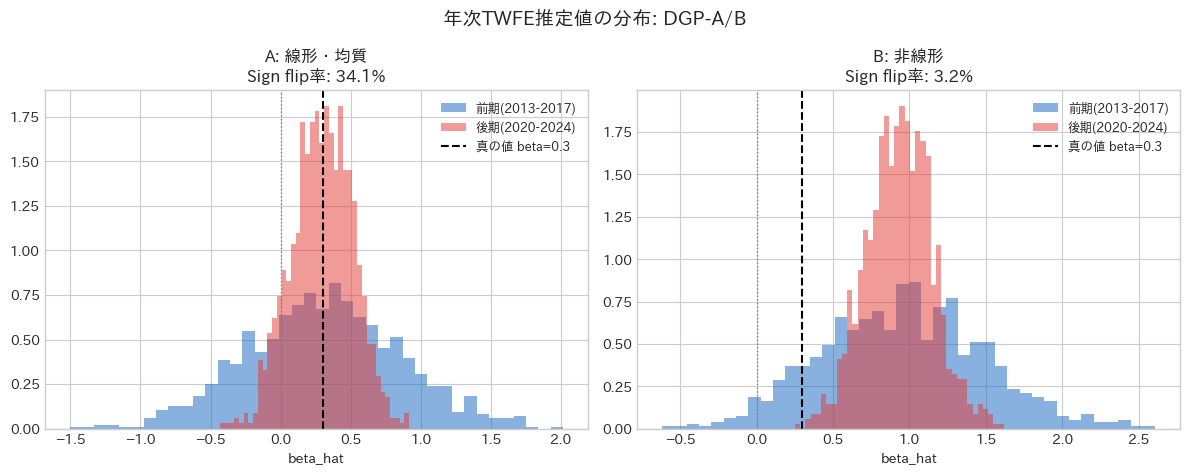

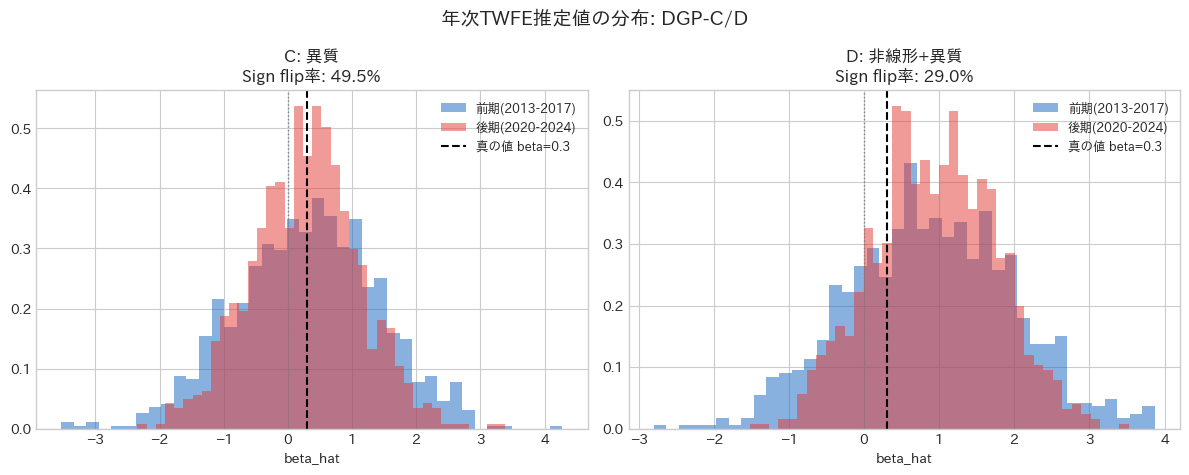

In [6]:
# Figure 1: DGP別のbeta_hat分布（前期 vs 後期）
def plot_beta_distribution_subset(items, filename, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=False)

    for ax, (dgp_name, res) in zip(axes, items):
        ax.hist(res['early'], bins=40, alpha=0.5, color='#1565C0',
                label='前期(2013-2017)', density=True)
        ax.hist(res['late'], bins=40, alpha=0.5, color='#E53935',
                label='後期(2020-2024)', density=True)
        ax.axvline(BETA_TRUE, color='black', linestyle='--', linewidth=1.5,
                   label=f'真の値 beta={BETA_TRUE}')
        ax.axvline(0, color='gray', linestyle=':', linewidth=1)
        ax.set_title(f'{dgp_name}\nSign flip率: {res["flip_rate"]:.1%}', fontsize=12)
        ax.set_xlabel('beta_hat')
        ax.legend(fontsize=9)

    fig.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../output/figures/{filename}', dpi=150, bbox_inches='tight')
    plt.show()

items = list(results.items())
plot_beta_distribution_subset(
    items[:2],
    '04_mc_beta_distribution_ab.png',
    '年次TWFE推定値の分布: DGP-A/B'
)
plot_beta_distribution_subset(
    items[2:],
    '04_mc_beta_distribution_cd.png',
    '年次TWFE推定値の分布: DGP-C/D'
)


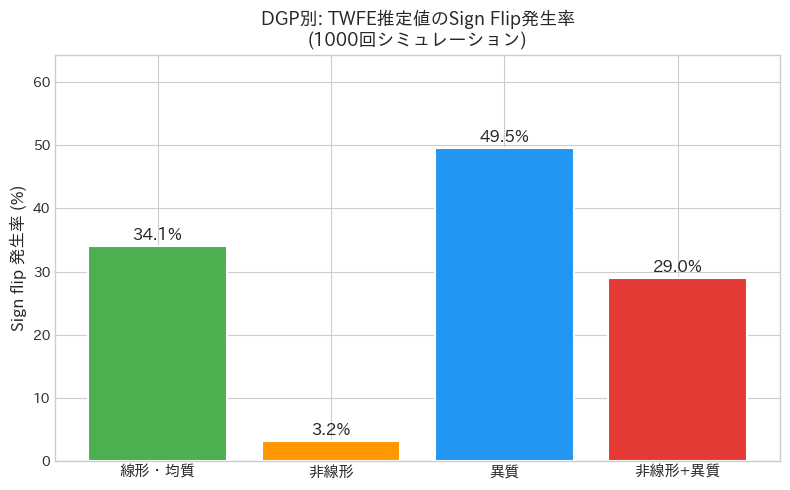

In [7]:
# Figure 2: Sign flip率のまとめ
fig, ax = plt.subplots(figsize=(8, 5))

dgp_names = list(results.keys())
flip_rates = [results[n]['flip_rate'] * 100 for n in dgp_names]
colors = ['#4CAF50', '#FF9800', '#2196F3', '#E53935']

bars = ax.bar(range(len(dgp_names)), flip_rates, color=colors, edgecolor='white', linewidth=1.5)

for bar, rate in zip(bars, flip_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{rate:.1f}%', ha='center', fontsize=12, fontweight='bold')

ax.set_xticks(range(len(dgp_names)))
ax.set_xticklabels([n.split(':')[1].strip() for n in dgp_names], fontsize=11)
ax.set_ylabel('Sign flip 発生率 (%)', fontsize=12)
ax.set_title('DGP別: TWFE推定値のSign Flip発生率\n(1000回シミュレーション)', fontsize=13, fontweight='bold')
ax.set_ylim(0, max(flip_rates) * 1.3)

plt.tight_layout()
plt.savefig('../output/figures/04_mc_signflip_rate.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 6: 境界分析（Heatmap）

heterogeneityの強さ(σ_het)と非線形の強さ(κ)を連続的に変化させ、
P(sign flip)がどう変わるかを見る。

In [8]:
# Grid search
kappas = np.linspace(0, 0.15, 8)
sigmas = np.linspace(0, 1.5, 8)
N_REP_HEAT = 500  # lighter for grid search

flip_grid = np.zeros((len(sigmas), len(kappas)))

for i, sh in enumerate(tqdm(sigmas, desc='heatmap')):
    for j, kp in enumerate(kappas):
        flips = 0
        for r in range(N_REP_HEAT):
            Y = generate_Y(d, pref_idx, ym_idx, N_pref, N_time,
                          kappa=kp, sigma_het=sh)
            b_e = twfe_beta(Y[early_mask], d_early, pref_early, ym_early)
            b_l = twfe_beta(Y[late_mask], d_late, pref_late, ym_late)
            if np.sign(b_e) != np.sign(b_l):
                flips += 1
        flip_grid[i, j] = flips / N_REP_HEAT

print('Heatmap計算完了')

heatmap:   0%|          | 0/8 [00:00<?, ?it/s]

heatmap:  12%|█▎        | 1/8 [00:15<01:49, 15.70s/it]

heatmap:  25%|██▌       | 2/8 [00:31<01:34, 15.75s/it]

heatmap:  38%|███▊      | 3/8 [00:45<01:15, 15.04s/it]

heatmap:  50%|█████     | 4/8 [00:54<00:50, 12.51s/it]

...

heatmap:  75%|███████▌  | 6/8 [01:06<00:17,  8.92s/it]

heatmap:  88%|████████▊ | 7/8 [01:13<00:08,  8.30s/it]

heatmap: 100%|██████████| 8/8 [01:20<00:00,  7.69s/it]

heatmap: 100%|██████████| 8/8 [01:20<00:00, 10.04s/it]

Heatmap計算完了


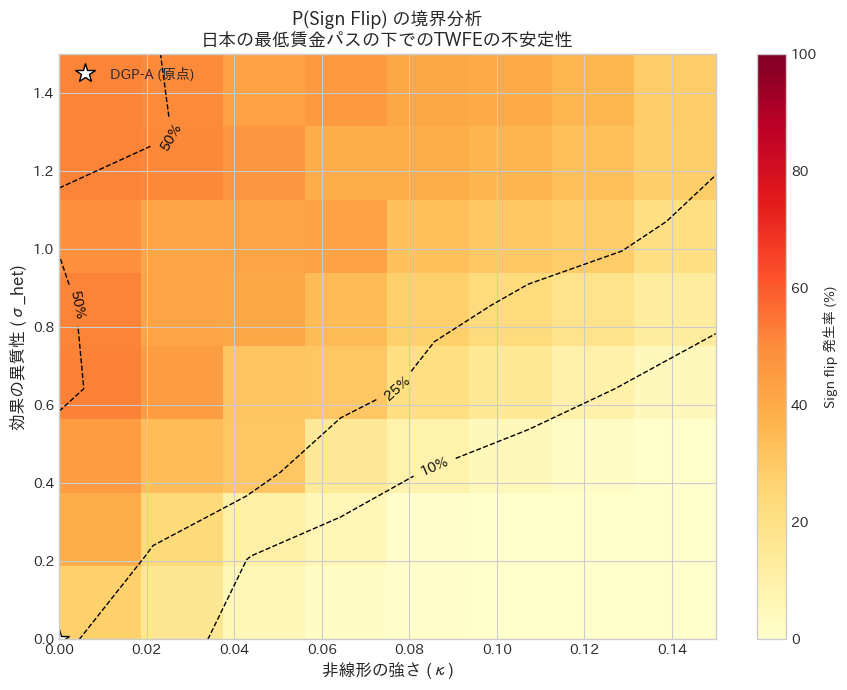

In [9]:
# Figure 3: Heatmap
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(flip_grid * 100, aspect='auto', origin='lower',
               cmap='YlOrRd', vmin=0, vmax=100,
               extent=[kappas[0], kappas[-1], sigmas[0], sigmas[-1]])

cbar = plt.colorbar(im, ax=ax, label='Sign flip 発生率 (%)')

# Contour lines
cs = ax.contour(kappas, sigmas, flip_grid * 100,
                levels=[10, 25, 50], colors='black', linewidths=1, linestyles='--')
ax.clabel(cs, fmt='%d%%', fontsize=10)

ax.set_xlabel('非線形の強さ (κ)', fontsize=12)
ax.set_ylabel('効果の異質性 (σ_het)', fontsize=12)
ax.set_title('P(Sign Flip) の境界分析\n日本の最低賃金パスの下でのTWFEの不安定性',
             fontsize=13, fontweight='bold')

# Mark DGP-A position
ax.plot(0, 0, 'w*', markersize=15, markeredgecolor='black', label='DGP-A (原点)')
ax.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig('../output/figures/04_mc_signflip_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 7: Bias分析（estimation error vs estimand problem）

In [10]:
# Biasサマリー
print('='*70)
print(f'{"DGP":<20} {"Bias(full)":>10} {"RMSE":>10} {"Flip率":>10}')
print('-'*70)
for dgp_name, res in results.items():
    bias = res['full'].mean() - BETA_TRUE
    rmse = np.sqrt(((res['full'] - BETA_TRUE)**2).mean())
    flip = res['flip_rate']
    print(f'{dgp_name:<20} {bias:>10.4f} {rmse:>10.4f} {flip:>10.1%}')
print('='*70)
print(f'真の値: β = {BETA_TRUE}')

DGP                  Bias(full)       RMSE      Flip率
----------------------------------------------------------------------
A: 線形・均質                -0.0031     0.1161      34.1%
B: 非線形                   0.5967     0.6090       3.2%
C: 異質                   -0.0563     1.0496      49.5%
D: 非線形+異質                0.5965     1.1974      29.0%
真の値: β = 0.3


In [11]:
# 結果をCSV保存
rows = []
for dgp_name, res in results.items():
    rows.append({
        'dgp': dgp_name,
        'beta_true': BETA_TRUE,
        'beta_full_mean': res['full'].mean(),
        'beta_full_std': res['full'].std(),
        'beta_early_mean': res['early'].mean(),
        'beta_late_mean': res['late'].mean(),
        'bias': res['full'].mean() - BETA_TRUE,
        'rmse': np.sqrt(((res['full'] - BETA_TRUE)**2).mean()),
        'sign_flip_rate': res['flip_rate'],
    })
pd.DataFrame(rows).to_csv('../output/04_mc_results.csv', index=False)
print('Saved: output/04_mc_results.csv')

# Heatmap data
heat_df = pd.DataFrame(flip_grid, index=[f'{s:.2f}' for s in sigmas],
                       columns=[f'{k:.3f}' for k in kappas])
heat_df.to_csv('../output/04_mc_heatmap.csv')
print('Saved: output/04_mc_heatmap.csv')

Saved: output/04_mc_results.csv
Saved: output/04_mc_heatmap.csv


## Step 8: dcDH vs TWFEのMC内比較

年次パネル上でTWFEとdcDHの両方を回し、sign flip率を比較する。
dcDHがTWFEよりflip率が低ければ「推定手法の問題」の証拠になる。

In [12]:
# 年次パネルの構造を読み込み
annual = pd.read_csv('../data/annual_panel.csv')
clean_annual = annual[annual.mw_year.isin([2013,2014,2015,2016,2017,2020,2021,2022,2023,2024])].copy()
clean_annual = clean_annual.sort_values(['pref_code', 'mw_year']).reset_index(drop=True)

a_prefs = sorted(clean_annual.pref_code.unique())
a_years = sorted(clean_annual.mw_year.unique())
a_pref_to_idx = {p: i for i, p in enumerate(a_prefs)}
a_year_to_idx = {t: i for i, t in enumerate(a_years)}

clean_annual['pref_idx'] = clean_annual.pref_code.map(a_pref_to_idx)
clean_annual['year_idx'] = clean_annual.mw_year.map(a_year_to_idx)

a_d = clean_annual.log_mw.values
a_pref_idx = clean_annual.pref_idx.values
a_year_idx = clean_annual.year_idx.values
a_N_pref = len(a_prefs)
a_N_time = len(a_years)

a_early = (clean_annual.mw_year <= 2017).values
a_late = (clean_annual.mw_year >= 2020).values

# year pairs for dcDH
year_pairs = [(a_years[j], a_years[j+1]) for j in range(a_N_time-1)]
early_pair_mask = np.array([y2 <= 2017 and (y2-y1)==1 for y1,y2 in year_pairs])
late_pair_mask = np.array([y1 >= 2020 and (y2-y1)==1 for y1,y2 in year_pairs])

print(f'Annual panel: {len(clean_annual)} obs, {a_N_pref} prefs, {a_N_time} years')
print(f'Early pairs: {early_pair_mask.sum()}, Late pairs: {late_pair_mask.sum()}')

Annual panel: 470 obs, 47 prefs, 10 years
Early pairs: 4, Late pairs: 4


In [13]:
def dcdh_theta_fast(D1, delta_D, delta_Y):
    """dcDH estimator (fast, linear spec)"""
    n = len(D1)
    S = np.sign(delta_D)
    X = np.column_stack([np.ones(n), D1, delta_D, D1 * delta_D])
    X0 = np.column_stack([np.ones(n), D1, np.zeros(n), np.zeros(n)])
    lam = np.linalg.lstsq(X, delta_Y, rcond=None)[0]
    g0 = X0 @ lam
    return np.sum(S * (delta_Y - g0)) / np.sum(np.abs(delta_D))

In [14]:
N_REP_COMP = 1000

# Pre-compute fixed treatment structure
a_d_mat = a_d.reshape(a_N_pref, a_N_time)
dD_mat = np.diff(a_d_mat, axis=1)  # (47, 9)
D1_mat = a_d_mat[:, :-1]            # (47, 9)

comp_results = {}

for dgp_name, params in DGPS.items():
    twfe_e = np.zeros(N_REP_COMP)
    twfe_l = np.zeros(N_REP_COMP)
    dcdh_e = np.zeros(N_REP_COMP)
    dcdh_l = np.zeros(N_REP_COMP)

    for r in tqdm(range(N_REP_COMP), desc=dgp_name):
        Y = generate_Y(a_d, a_pref_idx, a_year_idx, a_N_pref, a_N_time, **params)

        # TWFE
        twfe_e[r] = twfe_beta(Y[a_early], a_d[a_early], a_pref_idx[a_early], a_year_idx[a_early])
        twfe_l[r] = twfe_beta(Y[a_late], a_d[a_late], a_pref_idx[a_late], a_year_idx[a_late])

        # dcDH
        Y_mat = Y.reshape(a_N_pref, a_N_time)
        dY_mat = np.diff(Y_mat, axis=1)  # (47, 9)

        for mask, arr, label in [(early_pair_mask, dcdh_e, 'e'), (late_pair_mask, dcdh_l, 'l')]:
            dY_sub = dY_mat[:, mask].flatten()
            D1_sub = D1_mat[:, mask].flatten()
            dD_sub = dD_mat[:, mask].flatten()
            pos = dD_sub > 0
            if pos.sum() > 10:
                val = dcdh_theta_fast(D1_sub[pos], dD_sub[pos], dY_sub[pos])
                if label == 'e':
                    dcdh_e[r] = val
                else:
                    dcdh_l[r] = val

    twfe_flip = (np.sign(twfe_e) != np.sign(twfe_l)).mean()
    dcdh_flip = (np.sign(dcdh_e) != np.sign(dcdh_l)).mean()

    comp_results[dgp_name] = {'twfe_flip': twfe_flip, 'dcdh_flip': dcdh_flip}
    print(f'{dgp_name}: TWFE flip={twfe_flip:.1%}, dcDH flip={dcdh_flip:.1%}')

A: 線形・均質:   0%|          | 0/1000 [00:00<?, ?it/s]

A: 線形・均質:   4%|▍         | 45/1000 [00:00<00:02, 446.83it/s]

A: 線形・均質:  10%|█         | 100/1000 [00:00<00:01, 507.13it/s]

A: 線形・均質:  16%|█▌        | 160/1000 [00:00<00:01, 548.13it/s]

A: 線形・均質:  22%|██▏       | 219/1000 [00:00<00:01, 563.25it/s]

...

D: 非線形+異質:  88%|████████▊ | 875/1000 [00:01<00:00, 547.22it/s]

D: 非線形+異質:  93%|█████████▎| 931/1000 [00:01<00:00, 549.86it/s]

D: 非線形+異質:  99%|█████████▊| 987/1000 [00:01<00:00, 550.71it/s]

D: 非線形+異質: 100%|██████████| 1000/1000 [00:01<00:00, 545.14it/s]

D: 非線形+異質: TWFE flip=27.7%, dcDH flip=46.0%


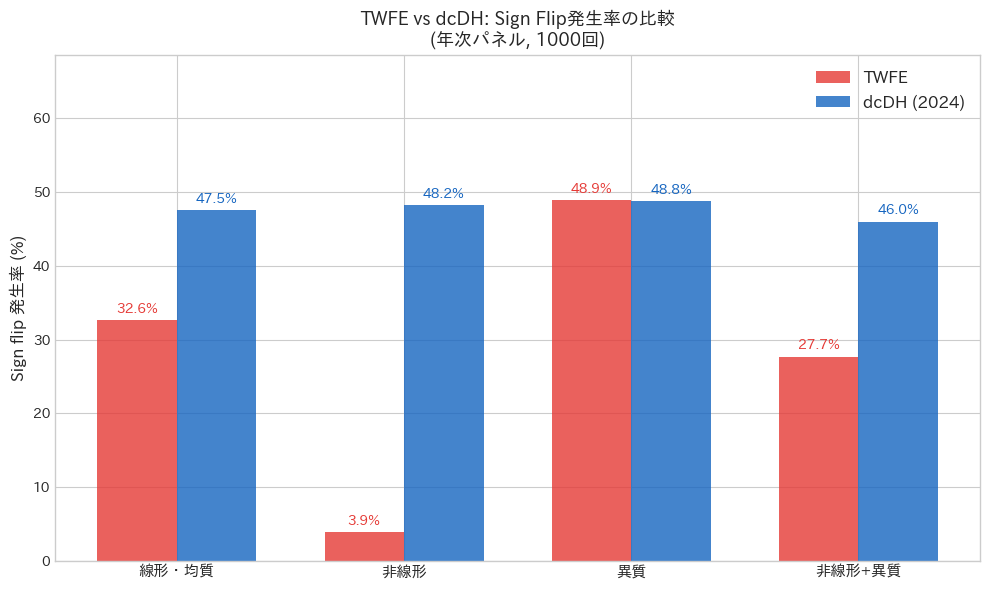

In [15]:
# Figure 4: TWFE vs dcDH sign flip comparison
fig, ax = plt.subplots(figsize=(10, 6))

dgp_labels = [n.split(':')[1].strip() for n in comp_results.keys()]
twfe_rates = [comp_results[n]['twfe_flip']*100 for n in comp_results]
dcdh_rates = [comp_results[n]['dcdh_flip']*100 for n in comp_results]

x = np.arange(len(dgp_labels))
width = 0.35

bars1 = ax.bar(x - width/2, twfe_rates, width, label='TWFE', color='#E53935', alpha=0.8)
bars2 = ax.bar(x + width/2, dcdh_rates, width, label='dcDH (2024)', color='#1565C0', alpha=0.8)

for bar, rate in zip(bars1, twfe_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{rate:.1f}%', ha='center', fontsize=10, fontweight='bold', color='#E53935')
for bar, rate in zip(bars2, dcdh_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{rate:.1f}%', ha='center', fontsize=10, fontweight='bold', color='#1565C0')

ax.set_xticks(x)
ax.set_xticklabels(dgp_labels, fontsize=11)
ax.set_ylabel('Sign flip \u767a\u751f\u7387 (%)', fontsize=12)
ax.set_title('TWFE vs dcDH: Sign Flip\u767a\u751f\u7387\u306e\u6bd4\u8f03\n(\u5e74\u6b21\u30d1\u30cd\u30eb, 1000\u56de)', fontsize=13, fontweight='bold')
ax.legend(fontsize=12)
ax.set_ylim(0, max(max(twfe_rates), max(dcdh_rates)) * 1.3 + 5)

plt.tight_layout()
plt.savefig('../output/figures/04_mc_twfe_vs_dcdh.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 9: パラメータ感度分析

β（真の効果）を変えても、異質性によるsign flipの結論は変わらないか確認。

In [16]:
betas_test = np.linspace(-0.5, 1.0, 7)
N_REP_SENS = 500

sens_results = []

for bt in tqdm(betas_test, desc='beta sensitivity'):
    flips = 0
    for r in range(N_REP_SENS):
        Y = generate_Y(d, pref_idx, ym_idx, N_pref, N_time,
                       beta=bt, kappa=0.0, sigma_het=0.5)
        b_e = twfe_beta(Y[early_mask], d[early_mask], pref_idx[early_mask], ym_idx[early_mask])
        b_l = twfe_beta(Y[late_mask], d[late_mask], pref_idx[late_mask], ym_idx[late_mask])
        if np.sign(b_e) != np.sign(b_l):
            flips += 1
    sens_results.append({'beta': bt, 'flip_rate': flips / N_REP_SENS})
    print(f'  beta={bt:.2f}: flip rate = {flips/N_REP_SENS:.1%}')

sens_df = pd.DataFrame(sens_results)

beta sensitivity:   0%|          | 0/7 [00:00<?, ?it/s]

beta sensitivity:  14%|█▍        | 1/7 [00:00<00:04,  1.36it/s]

  beta=-0.50: flip rate = 40.4%


beta sensitivity:  29%|██▊       | 2/7 [00:01<00:03,  1.29it/s]

  beta=-0.25: flip rate = 47.2%


...

beta sensitivity:  86%|████████▌ | 6/7 [00:04<00:00,  1.30it/s]

  beta=0.75: flip rate = 32.4%


beta sensitivity: 100%|██████████| 7/7 [00:05<00:00,  1.29it/s]

beta sensitivity: 100%|██████████| 7/7 [00:05<00:00,  1.29it/s]

  beta=1.00: flip rate = 26.0%


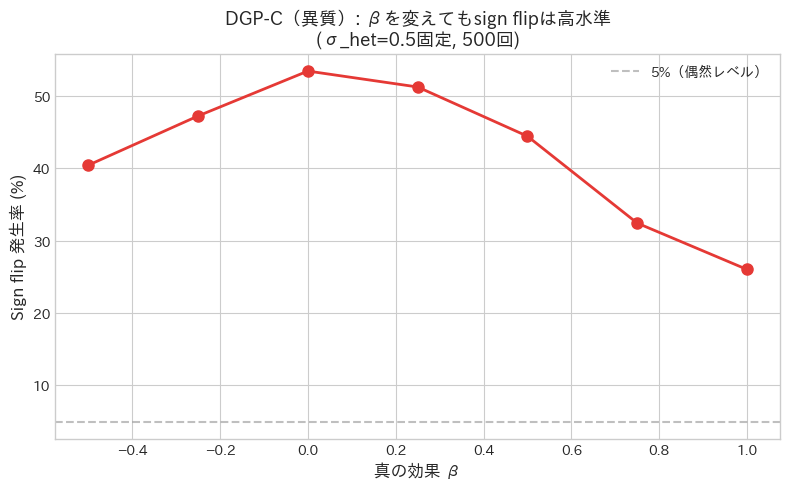

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(sens_df.beta, sens_df.flip_rate * 100, 'o-', color='#E53935',
        linewidth=2, markersize=8)
ax.axhline(5, color='gray', linestyle='--', alpha=0.5, label='5%\uff08\u5076\u7136\u30ec\u30d9\u30eb\uff09')
ax.set_xlabel('\u771f\u306e\u52b9\u679c \u03b2', fontsize=12)
ax.set_ylabel('Sign flip \u767a\u751f\u7387 (%)', fontsize=12)
ax.set_title('DGP-C\uff08\u7570\u8cea\uff09: \u03b2\u3092\u5909\u3048\u3066\u3082sign flip\u306f\u9ad8\u6c34\u6e96\n(\u03c3_het=0.5\u56fa\u5b9a, 500\u56de)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('../output/figures/04_mc_beta_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()